In [15]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/cleaned-off/off_filtered.csv
/kaggle/input/datasets/raesiow/nova-tf-idf/cm_tfidf.png
/kaggle/input/datasets/raesiow/nova-tf-idf/baseline_preds.csv
/kaggle/input/datasets/raesiow/nova-tf-idf/fpx_off_folds.csv
/kaggle/input/datasets/raesiow/nova-tf-idf/cm_text_vs_both.png
/kaggle/input/datasets/raesiow/nova-distilbert-oof/__huggingface_repos__.json
/kaggle/input/datasets/raesiow/nova-distilbert-oof/distilbert_oof.csv


In [16]:
nova = pd.read_csv("/kaggle/input/datasets/raesiow/nova-tf-idf/fpx_off_folds.csv", dtype={"off_code": str})  # NOVA rows + folds; barcode kept as text
oof = pd.read_csv("/kaggle/input/datasets/raesiow/nova-distilbert-oof/distilbert_oof.csv")  # DistilBERT out-of-fold probabilities

print(nova.shape)  # expect (1884, 22)
print(oof.shape)  # expect 1884 rows too
print(list(nova.columns))  # column names of the NOVA table
print(list(oof.columns))  # column names of the OOF table
oof.head()  # first 5 rows of the OOF table

(1884, 22)
(1884, 8)
['fpx_code', 'fpx_name', 'nova', 'off_code', 'off_name', 'source', 'score', 'cos', 'protein_g_f', 'fat_g_f', 'carb_excl_fiber_g_f', 'sugars_g_f', 'fiber_g_f', 'sat_fat_g_f', 'sodium_g_f', 'ingredients_text', 'categories_en', 'pnns_groups_2', 'image_url', 'nova_group', 'group', 'fold']
['fpx_code', 'off_code', 'nova', 'fold', 'p1', 'p2', 'p3', 'p4']


,fpx_code,off_code,nova,fold,p1,p2,p3,p4
0,57241000,16000124950,4,2,0.008805,0.002926,0.004129,0.984140
1,82101500,61483054577,2,0,0.971725,0.009705,0.011705,0.006865
2,92651000,815154020251,4,2,0.054991,0.004652,0.005985,0.934372
3,57125000,65633132115,4,1,0.005488,0.003497,0.004854,0.986161
4,83204000,5000157143075,4,0,0.009135,0.002442,0.003845,0.984577


In [17]:
from sklearn.metrics import f1_score  # macro-F1, our NOVA metric

print((nova["fpx_code"].values == oof["fpx_code"].values).all())  # True = same foods in same order
print((nova["fold"].values == oof["fold"].values).all())  # True = same fold for every row
print((nova["nova"].values == oof["nova"].values).all())  # True = same label for every row

prob_cols = ["p1", "p2", "p3", "p4"]  # names of the 4 probability columns
nova[prob_cols] = oof[prob_cols].values  # copy probabilities into the NOVA table by row position

pred = nova[prob_cols].values.argmax(axis=1) + 1  # biggest probability -> predicted group (columns 0-3 become NOVA 1-4)
scores = []  # one macro-F1 per fold goes here
for k in range(5):  # loop over the 5 folds
    in_fold = nova["fold"] == k  # True for rows in this test fold
    scores.append(f1_score(nova.loc[in_fold, "nova"], pred[in_fold], average="macro"))  # score this fold
print([round(s, 3) for s in scores])  # per-fold scores
print(round(pd.Series(scores).mean(), 3), "+/-", round(pd.Series(scores).std(), 3))  # mean +/- std

True
True
True
[0.767, 0.704, 0.747, 0.673, 0.612]
0.7 +/- 0.062


In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier  # the GBM model

nut_fpx = ["protein_g_f", "fat_g_f", "carb_excl_fiber_g_f", "sugars_g_f", "fiber_g_f", "sat_fat_g_f", "sodium_g_f"]  # 7 FoodProX nutrients

def run_gbm(feature_cols):  # train + test one GBM per fold, using the given columns
    pred_all = pd.Series(0, index=nova.index)  # one prediction per row, filled fold by fold
    scores = []  # one macro-F1 per fold
    for k in range(5):  # loop over the 5 folds
        test = nova["fold"] == k  # True = test row this time
        train = ~test  # the other 4 folds are training rows
        gbm = HistGradientBoostingClassifier(class_weight="balanced", max_iter=200, learning_rate=0.05, random_state=42)  # a FRESH model each fold, fixed settings
        gbm.fit(nova.loc[train, feature_cols], nova.loc[train, "nova"])  # learn from training folds only
        pred_all[test] = gbm.predict(nova.loc[test, feature_cols])  # predict the unseen fold
        scores.append(f1_score(nova.loc[test, "nova"], pred_all[test], average="macro"))  # score that fold
    print([round(s, 3) for s in scores])  # per-fold scores
    print(round(pd.Series(scores).mean(), 3), "+/-", round(pd.Series(scores).std(), 3))  # mean +/- std
    return scores, pred_all  # give back scores and predictions

scores_nut_fpx, pred_nut_fpx = run_gbm(nut_fpx)  # run 1: FoodProX nutrients only
scores_bert_fpx, pred_bert_fpx = run_gbm(prob_cols + nut_fpx)  # run 2: DistilBERT probs + FoodProX nutrients

[0.826, 0.79, 0.686, 0.802, 0.796]
0.78 +/- 0.054
[0.788, 0.832, 0.762, 0.713, 0.714]
0.762 +/- 0.051


In [19]:
nut_names = ["protein_g", "fat_g", "carb_excl_fiber_g", "sugars_g", "fiber_g", "sat_fat_g", "sodium_g"]  # 7 OFF nutrient columns
off = pd.read_csv("/kaggle/input/cleaned-off/off_filtered.csv", usecols=["code"] + nut_names, dtype={"code": str})  # only barcode + nutrients; barcode as text
print(off.shape)  # how many OFF products
print(off["code"].duplicated().sum())  # duplicate barcodes (expect 0)

off = off.rename(columns={c: c + "_off" for c in nut_names})  # add "_off" so they don't clash with FoodProX names
nut_off = [c + "_off" for c in nut_names]  # list of the new OFF nutrient column names

nova = nova.drop(columns=nut_off, errors="ignore")  # remove old copies if this cell is run twice
nova = nova.merge(off, left_on="off_code", right_on="code", how="left")  # attach OFF nutrients by barcode, keeps nova's row order
nova = nova.drop(columns="code")  # drop the extra barcode column from OFF

print(nova.shape)  # should still be 1884 rows
print(nova["protein_g_off"].notna().sum())  # how many rows found their OFF product (hope 1884)
print(nova[nut_off].isna().sum())  # missing values per nutrient

(71298, 8)
0
(1884, 33)
1884
protein_g_off            0
fat_g_off                0
carb_excl_fiber_g_off    0
sugars_g_off             0
fiber_g_off              0
sat_fat_g_off            0
sodium_g_off             0
dtype: int64


In [20]:
scores_nut_off, pred_nut_off = run_gbm(nut_off)  # run 3: OFF nutrients only
scores_bert_off, pred_bert_off = run_gbm(prob_cols + nut_off)  # run 4: DistilBERT probs + OFF nutrients

[0.76, 0.715, 0.674, 0.748, 0.663]
0.712 +/- 0.043
[0.792, 0.785, 0.667, 0.699, 0.656]
0.72 +/- 0.065


              precision    recall  f1-score   support

           1      0.763     0.803     0.782       477
           2      0.725     0.607     0.661        61
           3      0.636     0.555     0.593       265
           4      0.882     0.897     0.890      1081

    accuracy                          0.816      1884
   macro avg      0.752     0.715     0.731      1884
weighted avg      0.812     0.816     0.813      1884



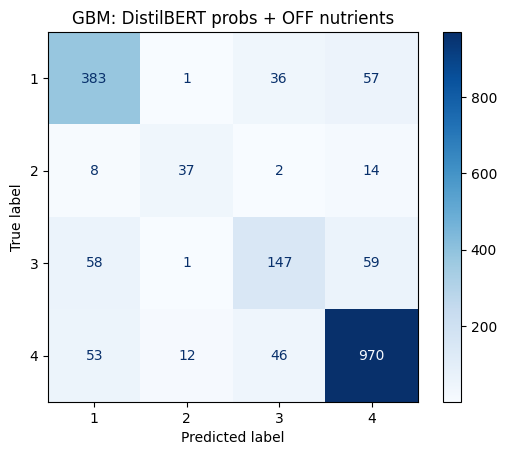

In [21]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay  # per-class scores + confusion matrix plot
import matplotlib.pyplot as plt  # for showing/saving the figure

print(classification_report(nova["nova"], pred_bert_off, digits=3))  # precision, recall, F1 for each NOVA group (all 5 test folds together)

ConfusionMatrixDisplay.from_predictions(nova["nova"], pred_bert_off, cmap="Blues")  # rows = true group, columns = predicted group
plt.title("GBM: DistilBERT probs + OFF nutrients")  # figure title
plt.savefig("cm_gbm_bert_off.png", dpi=200, bbox_inches="tight")  # save for the report
plt.show()  # display it


In [22]:
wrong3 = nova[(nova["nova"] == 3) & (pred_bert_off != 3)]  # true NOVA 3 rows the model got wrong
sample = wrong3.sample(10, random_state=1)  # 10 random ones (fixed seed so it's repeatable)
for _, row in sample.iterrows():  # go through them one by one
    print(row["fpx_name"], "|", row["off_name"], "| predicted", pred_bert_off[row.name])  # FoodProX food | OFF product | prediction
    print("   ", str(row["ingredients_text"])[:150])  # first 150 characters of the ingredients

pork cured ham boneless extra lean and regular unheated | premium hickory smoked traditional bone-in lean ham steak | predicted 4
    Pork, Water, Sugars (dextrose), Salt, Sodium phosphates, Potassium lactate, Potassium acetate, Sodium diacetate, Sodium nitrite, Smoke.
corn and sweet potatoes baby food strained | sweet potatoes | predicted 1
    Sweet potatoes.
cheese cottage lowfat 2% milkfat | cottage cheese | predicted 1
    skim milk, whole milk. cream, sea salt, lactase enzyme, live and active cultures (Lactococcus ssp., Lactobacillus ssp.) CONTAINS: pasteurized milk TRE
apricot cooked or canned drained solids | breakfast apricots in juice | predicted 1
    apricots, apple juice from concentrate, preservative (sulphur dioxide)
apricot cooked or canned juice pack | apricot halves in juice | predicted 1
    Apricot Halves, Grape Juice From Concentrate, Firming Agent (Calcium Chloride).
cheese cottage salted dry curd | cottage cheese | predicted 4
    Leche pasteurizada de vaca, prot

In [23]:
is_baby = nova["fpx_name"].str.contains("baby", case=False)  # True if the FoodProX name mentions baby food
print(is_baby.sum(), "baby food rows in total")  # across all NOVA groups
print(nova.loc[is_baby, "nova"].value_counts())  # which NOVA labels they carry
print(((nova["nova"] == 3) & is_baby).sum(), "of", (nova["nova"] == 3).sum(), "NOVA 3 rows are baby food")  # share inside NOVA 3

68 baby food rows in total
nova
3    49
1    10
4     9
Name: count, dtype: int64
49 of 265 NOVA 3 rows are baby food


In [24]:
off_baby = nova["off_name"].str.contains("baby", case=False)  # True if the OFF product name mentions baby
baby_mismatch = is_baby & ~off_baby  # baby food in FoodProX, but not in OFF
print(baby_mismatch.sum(), "baby mismatch rows")  # how many rows the rule catches

keep = ~baby_mismatch  # rows to score in the second version
scores_all, scores_clean = [], []  # per-fold macro-F1: all rows / without mismatches
for k in range(5):  # loop over the 5 folds
    test = nova["fold"] == k  # this fold's test rows
    scores_all.append(f1_score(nova.loc[test, "nova"], pred_bert_off[test], average="macro"))  # all test rows
    t = test & keep  # test rows that aren't baby mismatches
    scores_clean.append(f1_score(nova.loc[t, "nova"], pred_bert_off[t], average="macro"))  # without mismatches
print("all rows:  ", [round(s, 3) for s in scores_all], round(pd.Series(scores_all).mean(), 3))  # per fold + mean
print("no mismatch:", [round(s, 3) for s in scores_clean], round(pd.Series(scores_clean).mean(), 3))  # per fold + mean

print(f1_score(nova["nova"], pred_bert_off, average=None).round(3))  # per-class F1 on all rows (NOVA 1-4)
print(f1_score(nova.loc[keep, "nova"], pred_bert_off[keep], average=None).round(3))  # per-class F1 without mismatches

61 baby mismatch rows
all rows:   [0.792, 0.785, 0.667, 0.699, 0.656] 0.72
no mismatch: [0.803, 0.787, 0.675, 0.696, 0.678] 0.728
[0.782 0.661 0.593 0.89 ]
[0.8   0.661 0.603 0.892]


In [25]:
nova["pred_nut_fpx"] = pred_nut_fpx.values  # GBM, FoodProX nutrients only
nova["pred_bert_fpx"] = pred_bert_fpx.values  # GBM, probs + FoodProX nutrients
nova["pred_nut_off"] = pred_nut_off.values  # GBM, OFF nutrients only
nova["pred_bert_off"] = pred_bert_off.values  # GBM, probs + OFF nutrients (main result)
nova.to_csv("nova_gbm_preds.csv", index=False)  # all rows + predictions, for figures later


In [26]:
from sentence_transformers import SentenceTransformer  # library for sentence embeddings

minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")  # download + load MiniLM (~90 MB)
texts = nova["ingredients_text"].fillna("").astype(str).tolist()  # ingredient text as a plain list (empty text if missing)
emb = minilm.encode(texts, batch_size=64, show_progress_bar=True)  # 384 numbers per product (about 1-2 min on CPU)
print(emb.shape)  # expect (1884, 384)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/30 [00:00<?, ?it/s]

(1884, 384)


In [27]:
emb_cols = [f"emb_{i}" for i in range(emb.shape[1])]  # names emb_0 ... emb_383
emb_df = pd.DataFrame(emb, columns=emb_cols, index=nova.index)  # embeddings as a table, same row order as nova
nova = pd.concat([nova.drop(columns=emb_cols, errors="ignore"), emb_df], axis=1)  # attach (removing old copies if rerun)
print(nova.shape)  # 33 + 4 saved preds + 384 columns

scores_emb, pred_emb = run_gbm(emb_cols)  # run 5: MiniLM embeddings only
scores_emb_off, pred_emb_off = run_gbm(emb_cols + nut_off)  # run 6: embeddings + OFF nutrients

(1884, 421)
[0.688, 0.728, 0.737, 0.665, 0.581]
0.68 +/- 0.063
[0.752, 0.744, 0.752, 0.715, 0.619]
0.716 +/- 0.056


In [28]:
from sklearn.decomposition import PCA  # shrinks many columns into a few

def run_gbm_pca(extra_cols, n_comp=32):  # GBM on 32 PCA embedding columns (+ any extra columns)
    pred_all = pd.Series(0, index=nova.index)  # one prediction per row
    scores = []  # one macro-F1 per fold
    for k in range(5):  # loop over the 5 folds
        test = (nova["fold"] == k).values  # True = test row this time
        train = ~test  # the other 4 folds
        pca = PCA(n_components=n_comp, random_state=42)  # a fresh PCA each fold
        emb_train = pca.fit_transform(emb[train])  # learn the 32 directions from TRAINING rows only
        emb_test = pca.transform(emb[test])  # apply the same directions to the test rows
        x_train = np.hstack([emb_train, nova.loc[train, extra_cols].values])  # 32 PCA numbers + extra columns (training)
        x_test = np.hstack([emb_test, nova.loc[test, extra_cols].values])  # same for test
        gbm = HistGradientBoostingClassifier(class_weight="balanced", max_iter=200, learning_rate=0.05, random_state=42)  # same fixed settings as before
        gbm.fit(x_train, nova.loc[train, "nova"])  # learn from training folds
        pred_all[test] = gbm.predict(x_test)  # predict the unseen fold
        scores.append(f1_score(nova.loc[test, "nova"], pred_all[test], average="macro"))  # score this fold
    print([round(s, 3) for s in scores])  # per-fold scores
    print(round(pd.Series(scores).mean(), 3), "+/-", round(pd.Series(scores).std(), 3))  # mean +/- std
    return scores, pred_all  # scores and predictions

import numpy as np  # needed for hstack (joining columns side by side)
scores_pca, pred_pca = run_gbm_pca([])  # run 5b: PCA-32 embeddings only
scores_pca_off, pred_pca_off = run_gbm_pca(nut_off)  # run 6b: PCA-32 embeddings + OFF nutrients

[0.618, 0.676, 0.731, 0.686, 0.612]
0.665 +/- 0.05
[0.722, 0.763, 0.764, 0.755, 0.667]
0.734 +/- 0.041
